In [64]:
# 1. Import Library & Load Dataset
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dataset_path = 'dataset/index_data.csv' if os.path.exists('dataset/index_data.csv') else '../dataset/index_data.csv'
df = pd.read_csv(dataset_path)
print(f'Data berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom')
df.head()

Data berhasil dimuat: 1765 baris, 9 kolom


,Nama Suami,Nama Istri,Usia Suami,Usia Istri,Pendidikan Suami,Pendidikan Istri,Pekerjaan Suami,Pekerjaan Istri,Tahun
0,DEDE IRSAN,PUJI WIDIASTUTI,27,24,SLTP/SEDERAJAT,SLTA/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
1,SUPRIATNA MOCHAMMAD SAMAWI,SUSANTI,24,20,SLTA/SEDERAJAT,SLTP/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
2,SUHENDI,ELA LAELAWATI,40,39,SLTP/SEDERAJAT,SLTP/SEDERAJAT,WIRASWASTA,MENGURUS RUMAH TANGGA,2021
3,ARI HANA SUPARMAN,ANAH SUMIANGSIH,31,26,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,PELAJAR / MAHASISWA,2021
4,UJANG ALI ROHMAN,SITI HILMAH SHOFIYAH,24,21,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,BELUM / TIDAK BEKERJA,2021


In [ ]:
# 2. Preprocessing, Feature Engineering & Ground Truth Labeling
# Koreksi anomali usia 0
df.loc[df['Usia Istri'] == 0, 'Usia Istri'] = 20
df['Pendidikan Suami'] = df['Pendidikan Suami'].fillna('TIDAK DIKETAHUI')
df['Pendidikan Istri'] = df['Pendidikan Istri'].fillna('TIDAK DIKETAHUI')

# A. Pengelompokan Tingkat Kemapanan Ekonomi Pekerjaan Suami (Feature Engineering)
def kategori_pekerjaan_suami(p):
    p = str(p).upper().strip()
    if any(k in p for k in ['PNS', 'POLISI', 'TNI', 'TENTARA', 'BUMD', 'BUMN', 'DOKTER', 'DOSEN', 'GURU', 'PERAWAT', 'PERANGKAT DESA', 'PPPK', 'KARYAWAN SWASTA']):
        return 'Tetap/Mapan'
    elif any(k in p for k in ['WIRASWASTA', 'PEDAGANG', 'PERDAGANGAN', 'PETANI', 'PETERNAK', 'PETAMBAK', 'TAMBANG']):
        return 'Mandiri/Wiraswasta'
    elif any(k in p for k in ['BURUH', 'SOPIR', 'HONORER', 'SENI']):
        return 'Tidak Tetap/Buruh'
    else:
        return 'Tidak Bekerja'

# B. Pengelompokan Usia Berdasarkan Kategori Hukum & Kematangan (Binning Usia)
def kategori_usia(u):
    if u < 19:
        return '< 19 (Di Bawah Umur)'
    elif u <= 24:
        return '19-24 (Muda)'
    elif u <= 30:
        return '25-30 (Matang)'
    else:
        return '> 30 (Dewasa)'

df['Kategori_Pekerjaan_Suami'] = df['Pekerjaan Suami'].apply(kategori_pekerjaan_suami)
df['Kategori_Usia_Suami'] = df['Usia Suami'].apply(kategori_usia)
df['Kategori_Usia_Istri'] = df['Usia Istri'].apply(kategori_usia)

# C. Penentuan Label Target Kelayakan (UU Perkawinan No. 16/2019 + Kesiapan Ekonomi Suami):
# Syarat Layak: Suami >= 19 th DAN Istri >= 19 th DAN Suami memiliki pekerjaan (Mapan/Mandiri)
syarat_usia_sah = (df['Usia Suami'] >= 19) & (df['Usia Istri'] >= 19)
syarat_ekonomi_layak = df['Kategori_Pekerjaan_Suami'].isin(['Tetap/Mapan', 'Mandiri/Wiraswasta'])

df['Status_Kelayakan'] = np.where(syarat_usia_sah & syarat_ekonomi_layak, 'Layak', 'Tidak Layak')

print('Distribusi Label Status Kelayakan:')
print(df['Status_Kelayakan'].value_counts())
print(f"\nPersentase:\n{df['Status_Kelayakan'].value_counts(normalize=True) * 100}")

Distribusi Label Status Kelayakan:
Status_Kelayakan
Tidak Layak    1394
Layak           371
Name: count, dtype: int64

Persentase:
Status_Kelayakan
Tidak Layak    78.98017
Layak          21.01983
Name: proportion, dtype: float64


In [66]:
# 3. One-Hot Encoding Fitur & Split Data Latih/Uji
feature_cols = ['Kategori_Usia_Suami', 'Kategori_Usia_Istri', 'Kategori_Pekerjaan_Suami', 'Pendidikan Suami', 'Pendidikan Istri']

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X = encoder.fit_transform(df[feature_cols])
y = df['Status_Kelayakan']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Total fitur setelah One-Hot Encoding: {X.shape[1]} kolom biner')
print(f'Jumlah Data Latih: {X_train.shape[0]} | Data Uji: {X_test.shape[0]}')

Total fitur setelah One-Hot Encoding: 41 kolom biner
Jumlah Data Latih: 1412 | Data Uji: 353


In [67]:
# 4. Training Model Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=1.0) # alpha=1.0 adalah Laplace Smoothing
nb_model.fit(X_train, y_train)
print('Model Multinomial Naive Bayes berhasil dilatih!')

Model Multinomial Naive Bayes berhasil dilatih!


In [68]:
# 5. Evaluasi Model
y_pred = nb_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=['Layak', 'Tidak Layak'])

print('================ HASIL EVALUASI MODEL ================')
print(f'Akurasi: {acc * 100:.2f}%\n')
print('Confusion Matrix:')
print(cm)
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

================ HASIL EVALUASI MODEL ================
Akurasi: 99.43%

Confusion Matrix:
[[ 74   0]
 [  2 277]]

Classification Report:
              precision    recall  f1-score   support

       Layak       0.97      1.00      0.99        74
 Tidak Layak       1.00      0.99      1.00       279

    accuracy                           0.99       353
   macro avg       0.99      1.00      0.99       353
weighted avg       0.99      0.99      0.99       353



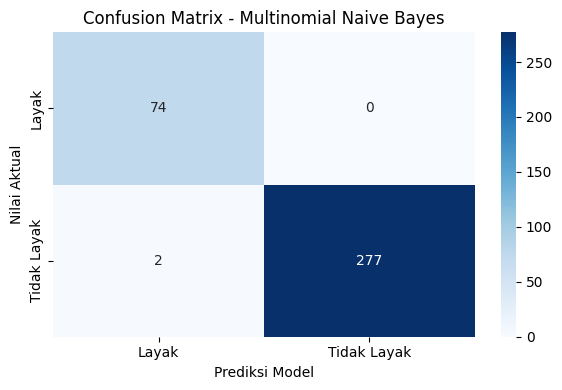

In [69]:
# 6. Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Layak', 'Tidak Layak'],
            yticklabels=['Layak', 'Tidak Layak'])
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.tight_layout()
plt.show()

In [70]:
# 7. 10-Fold Cross Validation
cv_scores = cross_val_score(nb_model, X, y, cv=10, scoring='accuracy')

print('Skor Akurasi 10-Fold CV:')
for i, score in enumerate(cv_scores, 1):
    print(f'  Fold {i:2d}: {score * 100:.2f}%')

print(f'\nRata-rata Akurasi (Mean CV): {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)')

Skor Akurasi 10-Fold CV:
  Fold  1: 100.00%
  Fold  2: 98.87%
  Fold  3: 97.74%
  Fold  4: 98.87%
  Fold  5: 100.00%
  Fold  6: 100.00%
  Fold  7: 98.86%
  Fold  8: 100.00%
  Fold  9: 99.43%
  Fold 10: 98.86%

Rata-rata Akurasi (Mean CV): 99.26% (+/- 0.72%)


In [71]:
# 8. Simulasi Prediksi Data Pasangan Baru (Fungsi Prediksi Praktis)
def prediksi_kelayakan(usia_suami, usia_istri, pekerjaan_suami, pendidikan_suami, pendidikan_istri):
    input_raw = pd.DataFrame([{
        'Kategori_Usia_Suami': kategori_usia(usia_suami),
        'Kategori_Usia_Istri': kategori_usia(usia_istri),
        'Kategori_Pekerjaan_Suami': kategori_pekerjaan_suami(pekerjaan_suami),
        'Pendidikan Suami': pendidikan_suami,
        'Pendidikan Istri': pendidikan_istri
    }])
    input_encoded = encoder.transform(input_raw[feature_cols])
    hasil = nb_model.predict(input_encoded)[0]
    prob = dict(zip(nb_model.classes_, [round(p * 100, 2) for p in nb_model.predict_proba(input_encoded)[0]]))
    return hasil, prob

# Uji Coba Kasus 1: Usia di bawah 19 tahun & Buruh Harian Lepas
hasil_1, prob_1 = prediksi_kelayakan(17, 15, 'BURUH HARIAN LEPAS', 'SLTA/SEDERAJAT', 'SLTP/SEDERAJAT')
print('--- UJI KASUS 1 (Usia 17 & 15, Buruh Harian Lepas) ---')
print(f'Hasil Prediksi : {hasil_1}')
print(f'Probabilitas   : {prob_1}\n')

# Uji Coba Kasus 2: Usia Ideal & Pekerjaan Mapan
hasil_2, prob_2 = prediksi_kelayakan(27, 24, 'KARYAWAN SWASTA', 'SLTA/SEDERAJAT', 'SLTA/SEDERAJAT')
print('--- UJI KASUS 2 (Usia 27 & 24, Karyawan Swasta) ---')
print(f'Hasil Prediksi : {hasil_2}')
print(f'Probabilitas   : {prob_2}')

--- UJI KASUS 1 (Usia 17 & 15, Buruh Harian Lepas) ---
Hasil Prediksi : Tidak Layak
Probabilitas   : {np.str_('Layak'): np.float64(0.1), np.str_('Tidak Layak'): np.float64(99.9)}

--- UJI KASUS 2 (Usia 27 & 24, Karyawan Swasta) ---
Hasil Prediksi : Layak
Probabilitas   : {np.str_('Layak'): np.float64(86.22), np.str_('Tidak Layak'): np.float64(13.78)}


In [72]:
# 9. Menyimpan Model dan Preprocessor (.pkl)
models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(nb_model, os.path.join(models_dir, 'naive_bayes.pkl'))
joblib.dump(encoder, os.path.join(models_dir, 'preprocessor.pkl'))
joblib.dump(feature_cols, os.path.join(models_dir, 'features.pkl'))

print('Berhasil menyimpan model & preprocessor ke folder /models:')
print(f" - {os.path.join(models_dir, 'naive_bayes.pkl')}")
print(f" - {os.path.join(models_dir, 'preprocessor.pkl')}")
print(f" - {os.path.join(models_dir, 'features.pkl')}")

Berhasil menyimpan model & preprocessor ke folder /models:
 - models\naive_bayes.pkl
 - models\preprocessor.pkl
 - models\features.pkl


In [73]:
# 10. Pengujian Memuat (Load) Model & Preprocessor dari file .pkl
loaded_model = joblib.load(os.path.join(models_dir, 'naive_bayes.pkl'))
loaded_encoder = joblib.load(os.path.join(models_dir, 'preprocessor.pkl'))
loaded_features = joblib.load(os.path.join(models_dir, 'features.pkl'))

# Verifikasi uji prediksi menggunakan objek yang di-load dari file .pkl
test_input = pd.DataFrame([{
    'Kategori_Usia_Suami': '< 19 (Di Bawah Umur)',
    'Kategori_Usia_Istri': '< 19 (Di Bawah Umur)',
    'Kategori_Pekerjaan_Suami': 'Tidak Tetap/Buruh',
    'Pendidikan Suami': 'SLTA/SEDERAJAT',
    'Pendidikan Istri': 'SLTP/SEDERAJAT'
}])

test_X = loaded_encoder.transform(test_input[loaded_features])
pred_pkl = loaded_model.predict(test_X)[0]
print(f'Verifikasi Hasil Prediksi dari .pkl (Kasus Usia < 19 & Buruh): {pred_pkl}')

Verifikasi Hasil Prediksi dari .pkl (Kasus Usia < 19 & Buruh): Tidak Layak
